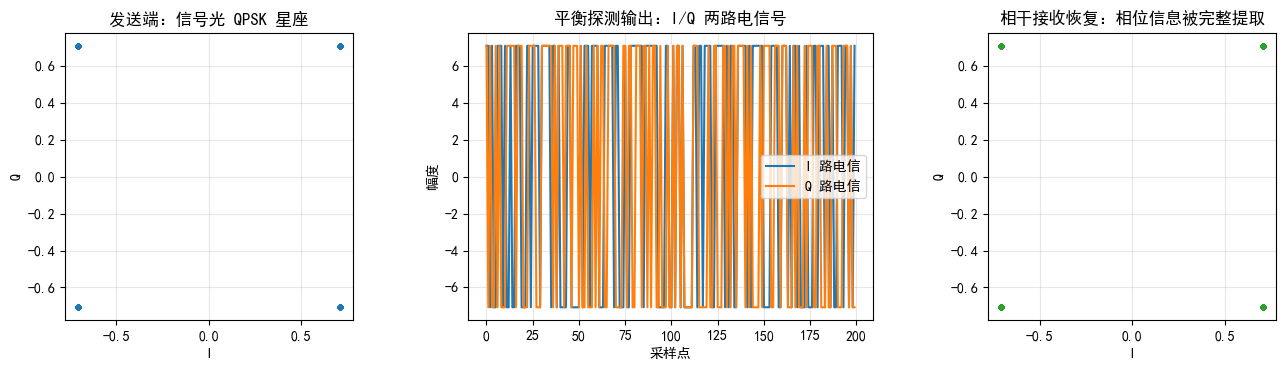

I/Q 恢复错误率 = 0.0000（应为 0）
验收：能说清『本振与信号光混频 → 相位差映射到 I/Q 幅度』

OptiSystem 实操步骤（对应本脚本的物理过程）：
1. 打开 OptiSystem → File → New → 从 Component Library 拖元件
2. 搭建链路：Laser(信号) → MZM(QPSK调制) → Fiber →
   Laser(本振LO) + 90° Optical Hybrid → Balanced PD ×2 → BER Analyzer
3. 关键参数：光纤长度 80km，入纤功率扫描 -5~+10 dBm
4. 运行 → 从 BER Analyzer 导出眼图、星座图、BER 数值
5. 保存工程为 coherent_link_v1.osd，截图结果


In [1]:
"""
W4 · 相干检测原理（Python 基带等效演示）+ OptiSystem 操作对照
用代码演示：本振光混频 → 90° 光混合 → 平衡探测 → 恢复 I/Q 两路
说明：真实相干链路在 OptiSystem 里搭（见配套文档），本脚本帮你建立物理直觉
运行：python w4_coherent.py
产出：figures/w4_coherent_iq.png
"""
import os
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
os.makedirs('figures', exist_ok=True)

# ===== 相干检测的数学本质 =====
# 信号光 Es = |Es|·exp(j·φs)，本振光 Elo = |Elo|·exp(j·φlo)
# 90° 光混合器输出：I ∝ Re(Es·Elo*) = |Es||Elo|cos(φs-φlo)
#                 Q ∝ Im(Es·Elo*) = |Es||Elo|sin(φs-φlo)
# 即：把光场相位信息搬移到电域的 I/Q 两路 —— 这是相干检测比直接检测强的原因

np.random.seed(3)
Nsym = 2000
# 生成 QPSK 信号光场（相位携带数据）
bits = np.random.randint(0, 2, 2*Nsym)
sym = ((1-2*bits[0::2]) + 1j*(1-2*bits[1::2])) / np.sqrt(2)

# 本振光：幅度大、相位固定（理想情况 φlo=0）
Elo = 5.0 * np.exp(1j*0)              # 本振幅度远大于信号

# 相干混频：把信号光与本振光做干涉
# 平衡探测后得到的电信号 ∝ 2·Re(Es·Elo*) 和 2·Im(Es·Elo*)
I_elec = 2 * np.real(sym * np.conj(Elo))
Q_elec = 2 * np.imag(sym * np.conj(Elo))

# 归一化恢复（实际中由 DSP 的幅度归一化完成）
I_norm = I_elec / (2*abs(Elo))
Q_norm = Q_elec / (2*abs(Elo))
rx = I_norm + 1j*Q_norm

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
ax[0].scatter(sym.real[::3], sym.imag[::3], s=8, alpha=0.5)
ax[0].set_aspect('equal'); ax[0].set_title('发送端：信号光 QPSK 星座')
ax[0].set_xlabel('I'); ax[0].set_ylabel('Q'); ax[0].grid(True, alpha=0.3)

ax[1].plot(I_elec[::10], label='I 路电信')
ax[1].plot(Q_elec[::10], label='Q 路电信')
ax[1].set_title('平衡探测输出：I/Q 两路电信号')
ax[1].set_xlabel('采样点'); ax[1].set_ylabel('幅度'); ax[1].legend(); ax[1].grid(True, alpha=0.3)

ax[2].scatter(rx.real[::3], rx.imag[::3], s=8, alpha=0.5, color='C2')
ax[2].set_aspect('equal'); ax[2].set_title('相干接收恢复：相位信息被完整提取')
ax[2].set_xlabel('I'); ax[2].set_ylabel('Q'); ax[2].grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('figures/w4_coherent_iq.png', dpi=120)
plt.show()

# 验证恢复是否正确
err = np.mean(np.round(rx.real) != np.round(sym.real)) + np.mean(np.round(rx.imag) != np.round(sym.imag))
print(f"I/Q 恢复错误率 = {err:.4f}（应为 0）")
print("验收：能说清『本振与信号光混频 → 相位差映射到 I/Q 幅度』\n")

print("=" * 60)
print("OptiSystem 实操步骤（对应本脚本的物理过程）：")
print("1. 打开 OptiSystem → File → New → 从 Component Library 拖元件")
print("2. 搭建链路：Laser(信号) → MZM(QPSK调制) → Fiber →")
print("   Laser(本振LO) + 90° Optical Hybrid → Balanced PD ×2 → BER Analyzer")
print("3. 关键参数：光纤长度 80km，入纤功率扫描 -5~+10 dBm")
print("4. 运行 → 从 BER Analyzer 导出眼图、星座图、BER 数值")
print("5. 保存工程为 coherent_link_v1.osd，截图结果")
print("=" * 60)
